# 05 · Evaluación
**Proyecto Visión por Computador — CRISP-DM etapa 5**

La evaluación responde a los objetivos definidos en la comprensión del negocio (notebook 01), ahora sobre el color continuo:

1. **Error perceptual** ΔE2000 entre el Lab estimado y el medido (objetivo principal).
2. **Nombre de tono y grupo** derivados del Lab (metas definidas en el notebook 01).
3. **Utilidad comercial:** ¿la referencia correcta del catálogo de colorantes aparece entre las 3 sugeridas?
4. **Robustez** en fotos de cliente simuladas (fondo, luz, compresión), por factor del dominio.
5. **Equidad por metadatos** (género, tipo de prenda) y casos multicolor.
6. **Explicabilidad** (Grad-CAM) y análisis de errores.

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from core import config
from core.datos import decodificar
from core.color import lab_a_rgb

config.RUTA_FIGURAS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight", "savefig.dpi": 150})
rng = np.random.default_rng(config.SEMILLA)

def guardar(nombre):
    plt.savefig(config.RUTA_FIGURAS / f"{nombre}.png")

from skimage import color as skcolor
from sklearn.metrics import f1_score
from core.preparacion import cargar_prendas, cargar_tabla, RUTA_TEST_REAL
from core.evaluacion import (resumen_delta_e, metricas_nombre, catalogo_simulado, metricas_catalogo,
                             nombres_desde_lab, delta_e, metricas_cabeza)
ok, df, msg = cargar_prendas(); print(msg)
bytes_por_id = df.set_index("id")["imagen_bytes"]
tabla, proto = cargar_tabla()
pred = pd.read_parquet(config.RUTA_RESULTADOS / "predicciones.parquet")
nombres_cab = pd.read_parquet(config.RUTA_RESULTADOS / "predicciones_nombre.parquet")
real = pd.read_parquet(RUTA_TEST_REAL).set_index("id")
test = tabla[(tabla["split"] == "test") & tabla["uso_evaluacion"]]
lab_cols = ["L_obj", "a_obj", "b_obj"]
catalogo, tipo_cat = catalogo_simulado(tabla.loc[(tabla["split"] == "train") & tabla["uso_entrenamiento"], lab_cols].to_numpy())
print(f"Catálogo de colorantes: {tipo_cat}, {len(catalogo)} referencias")
NOMBRES = {
    "E1_umbral_mediana": "E1 Umbral + mediana (línea base)",
    "segmentacion_kmeans": "E2 Segmentación + k-means",
    "segmentacion_kmeans_grayworld": "E2b Segmentación + k-means + gray-world",
    "ridge_hist_lab": "E3 Histograma Lab + ridge",
    "ridge_resnet50": "E4 ResNet-50 + ridge",
    "ridge_dinov2_s": "E5 DINOv2-S + ridge",
    "ridge_clip_b32": "E6 CLIP ViT-B/32 + ridge",
    "clip_zeroshot": "E7 CLIP zero-shot",
    "mobilenet_estandar": "E8 MobileNetV3 fine-tuning",
    "mobilenet_contexto_real": "E9 MobileNetV3 + contexto real",
    "mobilenet_e10": "E10 MobileNetV3 completa + tonos",
    "hibrida_e11": "E11 Híbrida: mide sobre los píxeles",
}
NOMBRES = {m: n for m, n in NOMBRES.items() if (pred["modelo"] == m).any()}   # E10 solo si ya se entrenó
REDES_NB = [m for m in ["mobilenet_estandar", "mobilenet_contexto_real", "mobilenet_e10", "hibrida_e11"] if m in NOMBRES]

21,361 prendas en el alcance textil (Apparel)


Catálogo de colorantes: simulado, 300 referencias


In [2]:
def evaluar(modelo, conjunto, subconjunto=None):
    if modelo == "techo":   # el color medido real como si fuera la predicción: límite de la evaluación por nombre
        p = test[lab_cols].set_axis(["L", "a", "b"], axis=1)
    else:
        p = pred[(pred["modelo"] == modelo) & (pred["conjunto"] == conjunto)].set_index("id")
    ids = test.index.intersection(p.index)
    if subconjunto is not None:
        ids = ids.intersection(subconjunto)
    p = p.loc[ids].dropna()
    ids = p.index
    if len(ids) == 0:
        return None
    lab_p, lab_r = p[["L", "a", "b"]].to_numpy(), test.loc[ids, lab_cols].to_numpy()
    de = delta_e(lab_p, lab_r)
    fila = {"modelo": NOMBRES.get(modelo, "Techo: color medido perfecto"), "conjunto": conjunto, "n": len(ids), **resumen_delta_e(de),
            **metricas_nombre(lab_p, test.loc[ids, "baseColour"], proto),
            **metricas_catalogo(lab_p, lab_r, catalogo)}
    top1 = nombres_desde_lab(lab_p, proto, k=1)[:, 0]
    fila["f1_grupo"] = f1_score(test.loc[ids, "grupo_color"], [config.TONO_A_GRUPO[x] for x in top1], average="macro")
    # nombre desde las cabezas de clasificación de la red (si las tiene)
    nc = nombres_cab[(nombres_cab["modelo"] == modelo) & (nombres_cab["conjunto"] == conjunto)].set_index("id")
    if len(nc):
        cab = metricas_cabeza(nc.loc[ids], test.loc[ids, "grupo_color"], test.loc[ids, "baseColour"])
        fila.update({f"{k}_cab": v for k, v in cab.items()})
    return fila

limpios = test.index[test["coherente"] & ~test["multicolor"].astype(bool)]
filas = []
for conj in ["test", "test_real"]:
    for m in NOMBRES:
        if m.startswith("segmentacion") and conj == "test":
            continue   # en fotos de catálogo es la propia definición del objetivo
        f = evaluar(m, conj, limpios)
        if f: filas.append(f)
techo = pd.DataFrame([evaluar("techo", "test", limpios)])
res = pd.DataFrame(filas)
cols = ["modelo", "conjunto", "n", "dE_mediana", "dE_media", "pct_dE<10", "acc_grupo", "f1_grupo", "top1_tono", "top3_tono",
        "acc_grupo_cab", "top1_tono_cab", "top3_tono_cab", "hit@1", "hit@3", "hit@3_tol", "sug_dE<=3", "sug_dE<=5", "dE_sugerida"]
cols = [c for c in cols if c in res]
pd.concat([techo, res])[cols].to_csv(config.RUTA_RESULTADOS / "metricas_principales.csv", index=False)
# modelo de referencia para el resto del análisis: la red con menor ΔE mediano en foto de cliente
MEJOR = min(REDES_NB, key=lambda m: res.loc[(res["modelo"] == NOMBRES[m]) & (res["conjunto"] == "test_real"), "dE_mediana"].iloc[0])
print("Modelo de referencia para el análisis detallado:", NOMBRES[MEJOR])
fmt = {c: "{:.1%}" for c in cols if c not in ("modelo", "conjunto", "n", "dE_mediana", "dE_media", "dE_sugerida", "f1_grupo")}
fmt.update({c: "{:.2f}" for c in ["dE_mediana", "dE_media", "dE_sugerida", "f1_grupo"]})
display(res[cols].style.format(fmt, na_rep="—").background_gradient(subset=["dE_mediana"], cmap="RdYlGn_r"))

Modelo de referencia para el análisis detallado: E11 Híbrida: mide sobre los píxeles


,modelo,conjunto,n,dE_mediana,dE_media,pct_dE<10,acc_grupo,f1_grupo,top1_tono,top3_tono,acc_grupo_cab,top1_tono_cab,top3_tono_cab,hit@1,hit@3,hit@3_tol,sug_dE<=3,sug_dE<=5,dE_sugerida
0,E1 Umbral + mediana (línea base),test,1806,5.59,9.36,65.6%,45.2%,0.42,36.0%,58.7%,—,—,—,29.7%,48.2%,53.3%,20.2%,40.3%,10.04
1,E3 Histograma Lab + ridge,test,1806,6.99,8.66,69.7%,53.5%,0.47,41.9%,69.0%,—,—,—,16.0%,35.2%,42.9%,12.6%,31.2%,8.64
2,E4 ResNet-50 + ridge,test,1806,10.96,12.04,42.7%,46.5%,0.38,34.3%,62.7%,—,—,—,7.3%,19.1%,24.9%,6.2%,16.1%,11.69
3,E5 DINOv2-S + ridge,test,1806,10.61,11.46,46.3%,53.2%,0.43,37.4%,68.1%,—,—,—,6.8%,21.2%,27.1%,5.3%,16.4%,10.98
4,E6 CLIP ViT-B/32 + ridge,test,1806,10.91,11.93,44.2%,50.2%,0.42,37.6%,65.7%,—,—,—,7.8%,20.3%,26.0%,5.8%,17.2%,11.55
5,E7 CLIP zero-shot,test,1806,11.70,17.22,44.7%,64.5%,0.57,45.2%,58.0%,—,—,—,5.0%,13.9%,18.4%,7.7%,18.1%,17.66
6,E8 MobileNetV3 fine-tuning,test,1806,3.25,4.03,95.5%,74.9%,0.59,60.7%,86.5%,89.3%,—,—,38.5%,70.8%,79.3%,32.7%,65.9%,4.70
7,E9 MobileNetV3 + contexto real,test,1806,3.34,4.21,94.9%,76.2%,0.61,62.6%,87.7%,89.2%,—,—,37.0%,67.7%,77.7%,31.6%,64.6%,4.82
8,E10 MobileNetV3 completa + tonos,test,1806,2.95,3.59,97.3%,77.0%,0.62,63.1%,88.8%,89.3%,83.8%,98.2%,41.1%,73.8%,82.7%,34.6%,69.7%,4.39
9,E11 Híbrida: mide sobre los píxeles,test,1806,0.73,1.51,98.7%,74.9%,0.60,60.2%,89.4%,89.3%,83.3%,97.2%,75.7%,93.7%,95.8%,56.3%,84.9%,3.34


**Cómo leer la tabla** (prendas de test coherentes y de un solo color):
* `dE_mediana`: ΔE2000 mediano entre el color estimado y el medido. Una referencia: ΔE < 5 es «muy parecido» y ΔE > 10 ya es otro tono para un observador.
* `acc_grupo` / `f1_grupo` / `top1_tono` / `top3_tono`: nombre derivado del Lab predicho por el prototipo más cercano (método de la línea base).
* `*_cab`: nombre predicho directamente por las **cabezas de clasificación** de la red (grupo en E8-E10; tono solo en E10).
* `hit@3`: la referencia más cercana al color real está entre las 3 sugeridas. `hit@3_tol`: alguna de las 3 sugeridas es **equivalente a la vista** a la mejor (≤ 1 ΔE más lejos del color real).
* `sug_dE<=3` / `sug_dE<=5`: la primera referencia sugerida queda a ese ΔE del color real. `dE_sugerida`: ΔE medio de esa sugerencia.

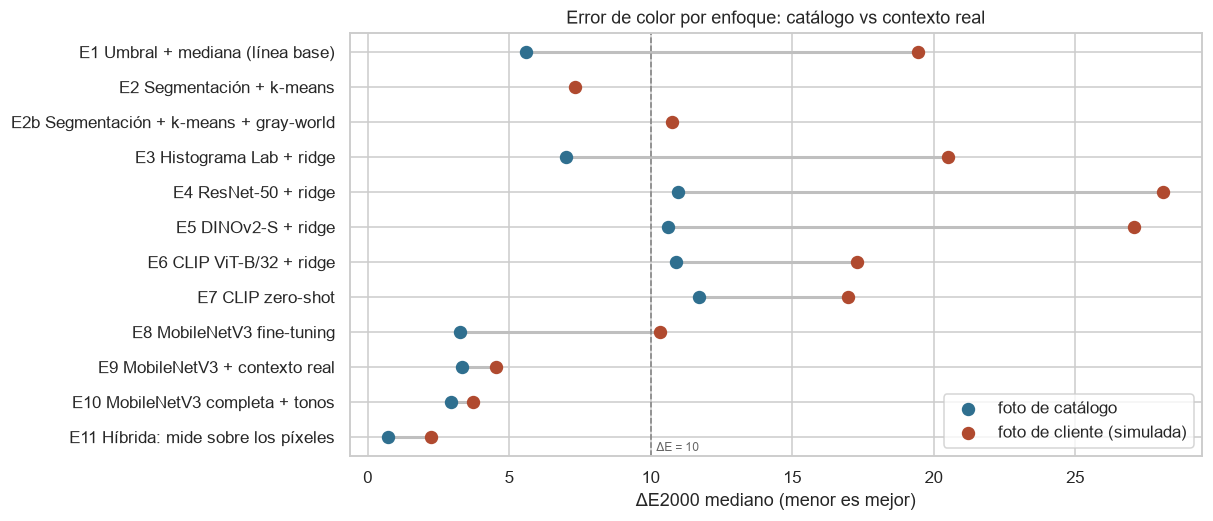

In [3]:
# Degradación catálogo -> foto de cliente
piv = res.pivot(index="modelo", columns="conjunto", values="dE_mediana").reindex([NOMBRES[m] for m in NOMBRES])
fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(piv))
for i, (m, r) in enumerate(piv.iterrows()):
    if pd.notna(r.get("test")):
        ax.plot([r["test"], r["test_real"]], [i, i], color="0.75", lw=2, zorder=1)
        ax.scatter(r["test"], i, color="#2F6F8F", s=60, zorder=2, label="foto de catálogo" if i == 0 else None)
    ax.scatter(r["test_real"], i, color="#B04A2F", s=60, zorder=2, label="foto de cliente (simulada)" if i == 0 else None)
ax.set_yticks(y); ax.set_yticklabels(piv.index); ax.invert_yaxis()
ax.axvline(10, color="0.5", ls="--", lw=1); ax.text(10.2, len(piv) - 0.6, "ΔE = 10", fontsize=8, color="0.4")
ax.set(xlabel="ΔE2000 mediano (menor es mejor)", title="Error de color por enfoque: catálogo vs contexto real")
ax.legend(loc="lower right"); guardar("p5_comparacion_modelos"); plt.show()

## 2. ¿Cuánto se puede lograr? El techo de la evaluación por nombre
Antes de juzgar los criterios por nombre, se evalúa el **color medido real** como si fuera una predicción perfecta: se le asigna el nombre del prototipo más cercano y se compara con la etiqueta `baseColour`. Si ese "modelo perfecto" no llega a la meta, la meta no es alcanzable con ese método, sin importar el modelo.

In [4]:
fmt_t = {c: "{:.1%}" for c in ["acc_grupo", "top1_tono", "top3_tono", "hit@3", "hit@3_tol", "sug_dE<=3", "sug_dE<=5"]}
display(techo[["modelo", "acc_grupo", "top1_tono", "top3_tono", "hit@3", "hit@3_tol", "sug_dE<=3", "sug_dE<=5"]].style.format(fmt_t))
cat_lab = catalogo[["L", "a", "b"]].to_numpy(float)
d = skcolor.deltaE_ciede2000(test.loc[limpios, lab_cols].to_numpy()[:, None, :], cat_lab[None]); d.sort(axis=1)
print(f"Catálogo: la referencia más cercana al color real está a ΔE {np.median(d[:, 0]):.2f} (mediana) y la segunda "
      f"apenas {np.median(d[:, 1] - d[:, 0]):.2f} más lejos: muchas referencias son indistinguibles a la vista.")

,modelo,acc_grupo,top1_tono,top3_tono,hit@3,hit@3_tol,sug_dE<=3,sug_dE<=5
0,Techo: color medido perfecto,75.0%,60.0%,89.8%,100.0%,100.0%,63.0%,92.2%


Catálogo: la referencia más cercana al color real está a ΔE 2.51 (mediana) y la segunda apenas 1.12 más lejos: muchas referencias son indistinguibles a la vista.


**Lectura.** Con el color perfecto, el nombre por prototipo acierta el grupo solo en ~75 % y el tono en ~60 %: el 36 % de las etiquetas no coincide con el color medido y los tonos vecinos se solapan en CIELAB (notebook 02). Por eso se agregaron dos mejoras de evaluación **sin cambiar las metas**:
1. **Nombre desde la red** (cabezas de clasificación entrenadas con la etiqueta), que aprende las convenciones de nombre del catálogo en lugar de depender de la distancia a un prototipo.
2. **Acierto tolerante en el catálogo**: dos referencias a menos de 1 ΔE son la misma para el laboratorio.

## 3. Cumplimiento de los criterios de éxito

In [5]:
def fila(m, conj):
    r = res[(res["modelo"] == NOMBRES[m]) & (res["conjunto"] == conj)]
    return r.iloc[0] if len(r) else None
base = fila("E1_umbral_mediana", "test_real")
ref_cat, ref_cli = fila(MEJOR, "test"), fila(MEJOR, "test_real")
t0 = techo.iloc[0]
def mejor_de(r, a, b):   # mejor entre el nombre por prototipo (a) y por cabeza (b), si existe
    return max(r[a], r[b]) if b in r.index and pd.notna(r[b]) else r[a]
criterios = pd.DataFrame([
    ["Grupo (13): accuracy", 0.90, t0["acc_grupo"], ref_cli["acc_grupo"], mejor_de(ref_cat, "acc_grupo", "acc_grupo_cab"), mejor_de(ref_cli, "acc_grupo", "acc_grupo_cab")],
    ["Grupo (13): F1-macro", 0.80, t0["f1_grupo"], ref_cli["f1_grupo"], mejor_de(ref_cat, "f1_grupo", "f1_grupo_cab"), mejor_de(ref_cli, "f1_grupo", "f1_grupo_cab")],
    ["Tono (46): top-1", 0.70, t0["top1_tono"], ref_cli["top1_tono"], mejor_de(ref_cat, "top1_tono", "top1_tono_cab"), mejor_de(ref_cli, "top1_tono", "top1_tono_cab")],
    ["Tono (46): top-3", 0.90, t0["top3_tono"], ref_cli["top3_tono"], mejor_de(ref_cat, "top3_tono", "top3_tono_cab"), mejor_de(ref_cli, "top3_tono", "top3_tono_cab")],
    ["Catálogo: referencia correcta en top-3", 0.80, 1.0, ref_cli["hit@3"], ref_cat["hit@3"], ref_cli["hit@3"]],
    ["Catálogo: equivalente a la vista en top-3", 0.80, 1.0, ref_cli["hit@3_tol"], ref_cat["hit@3_tol"], ref_cli["hit@3_tol"]],
], columns=["criterio", "meta", "techo (prototipo)", "cliente (prototipo)", "catálogo (mejor)", "cliente (mejor)"])
criterios["cumple en cliente"] = np.where(criterios["cliente (mejor)"] >= criterios["meta"], "sí",
                                         np.where(criterios["cliente (mejor)"] >= criterios["meta"] - 0.05, "casi", "no"))
print(f"Modelo: {NOMBRES[MEJOR]} · ΔE mediano en contexto real {ref_cli['dE_mediana']:.1f} (línea base E1: {base['dE_mediana']:.1f})")
criterios.to_csv(config.RUTA_RESULTADOS / "criterios.csv", index=False)
display(criterios.style.format({c: "{:.1%}" for c in criterios.columns[1:6]}))

Modelo: E11 Híbrida: mide sobre los píxeles · ΔE mediano en contexto real 2.2 (línea base E1: 19.5)


,criterio,meta,techo (prototipo),cliente (prototipo),catálogo (mejor),cliente (mejor),cumple en cliente
0,Grupo (13): accuracy,90.0%,75.0%,74.0%,89.3%,86.4%,casi
1,Grupo (13): F1-macro,80.0%,60.2%,58.9%,86.5%,82.8%,sí
2,Tono (46): top-1,70.0%,60.0%,59.9%,83.3%,80.2%,sí
3,Tono (46): top-3,90.0%,89.8%,86.7%,97.2%,96.6%,sí
4,Catálogo: referencia correcta en top-3,80.0%,100.0%,79.6%,93.7%,79.6%,casi
5,Catálogo: equivalente a la vista en top-3,80.0%,100.0%,87.5%,95.8%,87.5%,sí


**Lectura de los criterios (modelo E11, foto de cliente).**

| Criterio | Meta | Techo por prototipo | E9 (prototipo) | E10 | **E11** | ¿Cumple? |
|---|---|---|---|---|---|---|
| ΔE2000 mediano | — | 0 | 4,5 | 3,7 | **2,2** | E1 = 19,5 |
| Grupo (13): accuracy | ≥ 90 % | 75 % | 70 % | 86 % | **86 %** | casi |
| Grupo (13): F1-macro | ≥ 0,80 | 0,60 | 0,55 | 0,83 | **0,83** | sí |
| Tono (46): top-1 | ≥ 70 % | 60 % | 58 % | 80 % | **80 %** | sí |
| Tono (46): top-3 | ≥ 90 % | 90 % | 83 % | 97 % | **97 %** | sí |
| Referencia correcta (exacta) en top-3 | ≥ 80 % | 100 % | 51 % | 63 % | **80 %** | casi (79,6 %) |
| Referencia equivalente a la vista en top-3 | ≥ 80 % | 100 % | 62 % | 73 % | **88 %** | sí |

* Con el método por prototipo (nombre = prototipo más cercano al Lab) **ni un color perfecto** alcanza las metas de nombre: el techo es 75 % de grupo y 60 % de tono, porque el 36 % de las etiquetas no coincide con el color medido y los tonos vecinos se solapan. Las cabezas de clasificación (E10, E11) aprenden las convenciones de nombre del catálogo directamente de la imagen y superan ese techo.
* **E11 mejora sobre todo el color** (ΔE 3,7 → 2,2) y con él la **meta comercial**, que pasa a cumplirse (88 % con referencia equivalente; 80 % exacta). El nombre queda igual que en E10: depende de las etiquetas, no de la precisión del color.
* **Alcance de la cifra:** se mide en las 1.806 prendas de test coherentes y de un color. En **todo** el test (incluidas multicolor y etiquetas incoherentes) E11 da ΔE mediano 2,7, 70 % de grupo y 60 % de tono top-1; en las multicolor el ΔE sube a 6,0 (un solo color no las describe: para ellas se entrega la paleta).
* **Catálogo (0,7):** en fotos de catálogo E11 casi replica el procedimiento de medición (el objetivo se mide sobre esos mismos píxeles con fondo blanco), por eso la cifra relevante para el negocio es la de **foto de cliente**.

## 4. Robustez por factor del dominio (fotos de cliente simuladas)

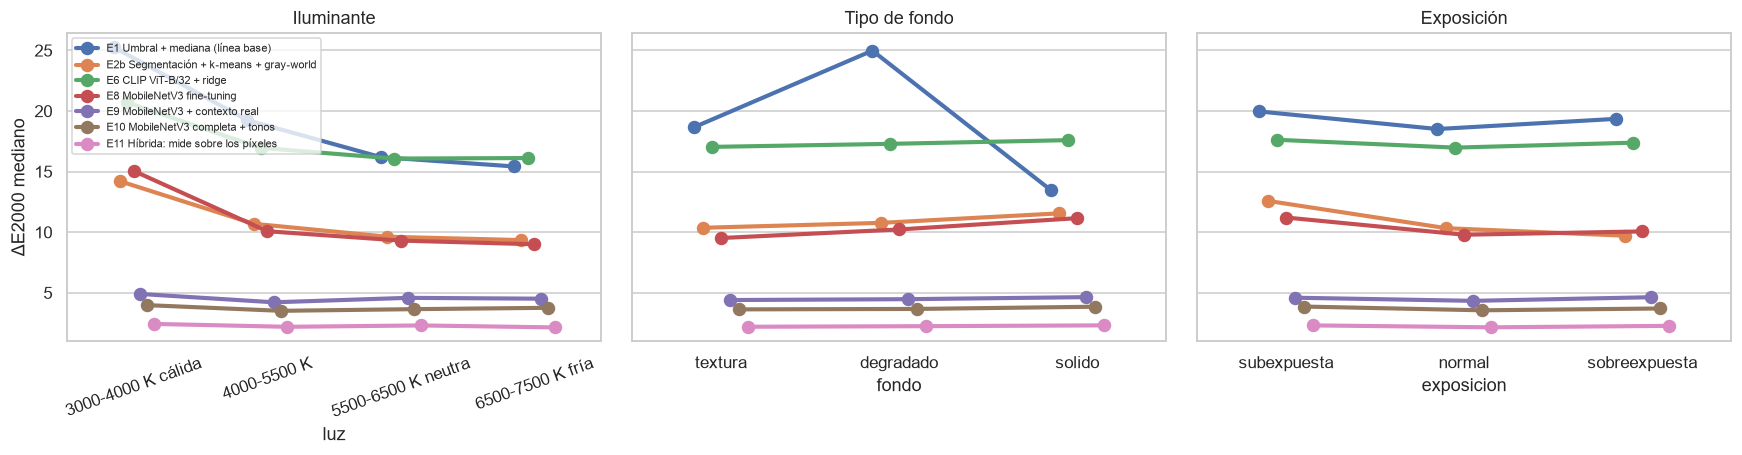

In [6]:
elegidos = [m for m in ["E1_umbral_mediana", "segmentacion_kmeans_grayworld", "ridge_clip_b32", "mobilenet_estandar",
                         "mobilenet_contexto_real", "mobilenet_e10", "hibrida_e11"] if m in NOMBRES]
pr = pred[pred["conjunto"] == "test_real"].set_index("id")
filas = []
for m in elegidos:
    p = pr[pr["modelo"] == m].loc[lambda x: x.index.isin(limpios)].dropna()
    de = delta_e(p[["L", "a", "b"]].to_numpy(), test.loc[p.index, lab_cols].to_numpy())
    filas.append(pd.DataFrame({"modelo": NOMBRES[m], "dE": de, "kelvin": real.loc[p.index, "kelvin"].values,
                               "fondo": real.loc[p.index, "fondo"].values, "jpeg": real.loc[p.index, "jpeg"].values,
                               "brillo": real.loc[p.index, "brillo"].values}))
rob = pd.concat(filas)
rob["luz"] = pd.cut(rob["kelvin"], [2999, 4000, 5500, 6500, 7501], labels=["3000-4000 K cálida", "4000-5500 K", "5500-6500 K neutra", "6500-7500 K fría"])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), sharey=True)
sns.pointplot(data=rob, x="luz", y="dE", hue="modelo", estimator=np.median, errorbar=None, ax=axes[0], dodge=.3)
sns.pointplot(data=rob, x="fondo", y="dE", hue="modelo", estimator=np.median, errorbar=None, ax=axes[1], dodge=.3, legend=False)
rob["exposicion"] = pd.cut(rob["brillo"], [0.7, 0.9, 1.05, 1.25], labels=["subexpuesta", "normal", "sobreexpuesta"])
sns.pointplot(data=rob, x="exposicion", y="dE", hue="modelo", estimator=np.median, errorbar=None, ax=axes[2], dodge=.3, legend=False)
axes[0].tick_params(axis="x", rotation=20); axes[0].set_ylabel("ΔE2000 mediano")
axes[0].legend(fontsize=7, loc="upper left")
for ax, t_ in zip(axes, ["Iluminante", "Tipo de fondo", "Exposición"]): ax.set_title(t_)
plt.tight_layout(); guardar("p5_robustez_factores"); plt.show()

## 5. Desagregación por metadatos y por tipo de prenda

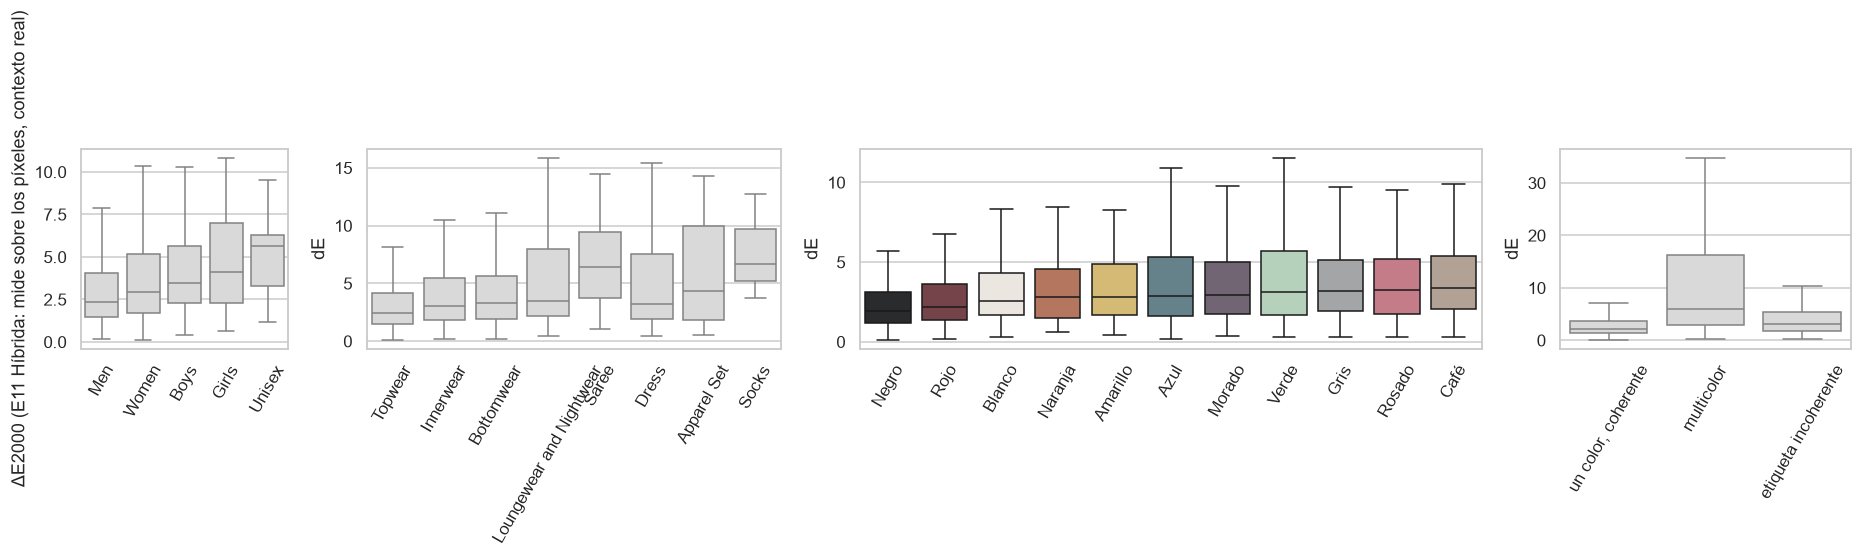

,ΔE mediano por género
gender,
Boys,3.47
Girls,4.11
Men,2.38
Unisex,5.65
Women,2.92


In [7]:
m_best = MEJOR
p = pr[pr["modelo"] == m_best].dropna()
ev = test.loc[test.index.intersection(p.index)].copy()
ev["dE"] = delta_e(p.loc[ev.index, ["L", "a", "b"]].to_numpy(), ev[lab_cols].to_numpy())
ev["tipo"] = np.select([ev["multicolor"].astype(bool), ~ev["coherente"]], ["multicolor", "etiqueta incoherente"], "un color, coherente")
fig, axes = plt.subplots(1, 4, figsize=(17, 4), gridspec_kw={"width_ratios": [1, 2, 3, 1.4]})
sns.boxplot(data=ev, x="gender", y="dE", ax=axes[0], color="0.85", fliersize=0, showfliers=False)
sns.boxplot(data=ev, x="subCategory", y="dE", ax=axes[1], color="0.85", showfliers=False)
orden = ev.groupby("grupo_color")["dE"].median().sort_values().index
sns.boxplot(data=ev, x="grupo_color", y="dE", order=orden, ax=axes[2], showfliers=False,
            palette=[lab_a_rgb(proto[proto["grupo"] == g][["L", "a", "b"]].median().to_numpy(float))[0] for g in orden])
sns.boxplot(data=ev, x="tipo", y="dE", ax=axes[3], color="0.85", showfliers=False)
for ax in axes: ax.tick_params(axis="x", rotation=60); ax.set_xlabel("")
axes[0].set_ylabel(f"ΔE2000 ({NOMBRES[m_best]}, contexto real)")
plt.tight_layout(); guardar("p5_desagregacion"); plt.show()
display(ev.groupby("gender")["dE"].median().round(2).to_frame("ΔE mediano por género"))

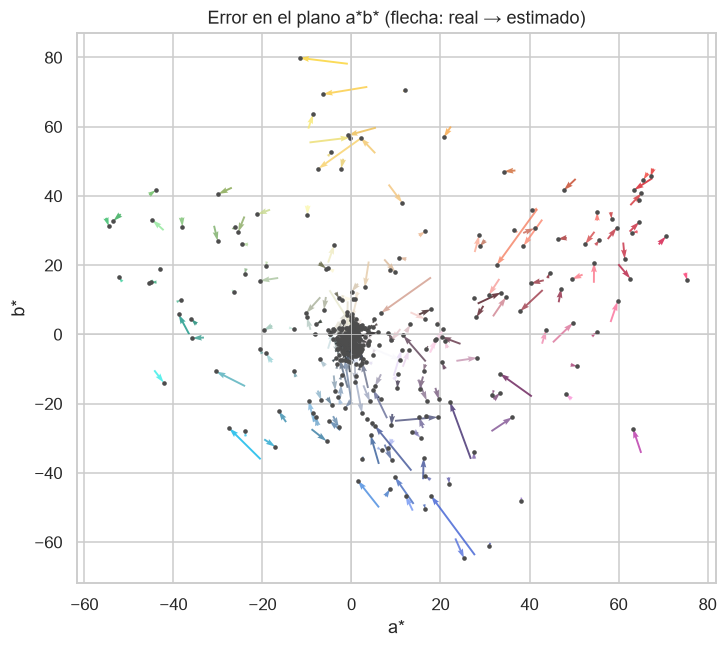

Sesgo medio: ΔL* = +0.1 · ΔC* = -0.5  (C* negativo = estima colores más apagados)


In [8]:
# Hacia dónde se equivoca: flechas del color real al estimado en el plano a*b*
mu = ev[ev["tipo"] == "un color, coherente"].sample(400, random_state=2)
pp = p.loc[mu.index]
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.quiver(mu["a_obj"], mu["b_obj"], pp["a"] - mu["a_obj"], pp["b"] - mu["b_obj"], angles="xy", scale_units="xy", scale=1,
          color=lab_a_rgb(mu[lab_cols].to_numpy()), width=0.003, alpha=.8)
ax.scatter(pp["a"], pp["b"], s=4, color="0.3")
ax.set(xlabel="a*", ylabel="b*", title="Error en el plano a*b* (flecha: real → estimado)")
ax.axhline(0, c="0.8", lw=.5); ax.axvline(0, c="0.8", lw=.5)
guardar("p5_flechas_error"); plt.show()
err = pd.DataFrame({"dL": pp["L"] - mu["L_obj"], "dC": np.hypot(pp["a"], pp["b"]) - np.hypot(mu["a_obj"], mu["b_obj"])})
print(f"Sesgo medio: ΔL* = {err['dL'].mean():+.1f} · ΔC* = {err['dC'].mean():+.1f}  (C* negativo = estima colores más apagados)")

## 6. Explicabilidad: ¿dónde mira el modelo? (Grad-CAM; en E11, su mapa de atención sobre los píxeles)

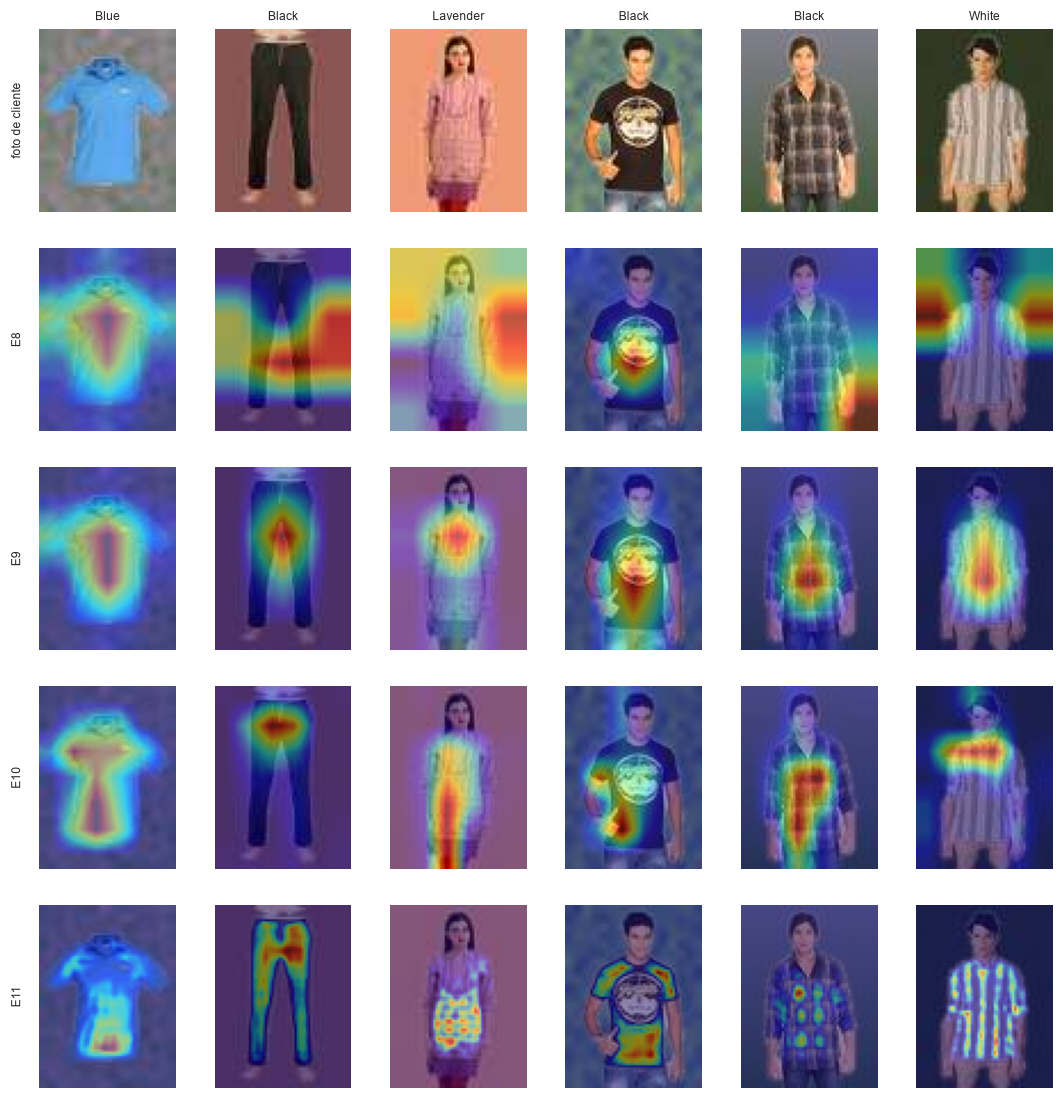

In [9]:
import json, torch
from core.modelos import cargar_red, preparar_tensor, grad_cam
from core.hibrida import predecir_foto
grupos = json.loads((config.RUTA_MODELOS / "grupos.json").read_text())
redes = {m: cargar_red(config.RUTA_MODELOS / f"{m}.pt", len(grupos))
         for m in REDES_NB}
ids = ev[ev["tipo"] == "un color, coherente"].sample(6, random_state=4).index
fig, axes = plt.subplots(1 + len(redes), 6, figsize=(12, 2.5 * (1 + len(redes))))
for k, pid in enumerate(ids):
    rgb = decodificar(real.at[pid, "imagen_bytes"])
    axes[0, k].imshow(rgb); axes[0, k].set_title(tabla.at[pid, "baseColour"], fontsize=8)
    for fila, (m, red) in zip(axes[1:], redes.items()):
        if getattr(red, "tipo", "") == "hibrida":
            cam = predecir_foto(red, rgb)[1]; cam = cam / cam.max()
        else:
            cam = grad_cam(red, preparar_tensor(rgb, tam=red.tam)[None])[0]
            cam = np.asarray(Image.fromarray((cam * 255).astype(np.uint8)).resize(rgb.shape[1::-1], Image.BILINEAR)) / 255
        fila[k].imshow(rgb); fila[k].imshow(cam, cmap="jet", alpha=.45)
for ax in axes.flat: ax.axis("off")
for fila, t_ in zip(axes[:, 0], ["foto de cliente"] + [NOMBRES[m].split(" ")[0] for m in redes]):
    fila.text(-0.12, 0.5, t_, transform=fila.transAxes, rotation=90, va="center", ha="right", fontsize=8)
guardar("p5_gradcam"); plt.show()

## 7. Análisis de errores

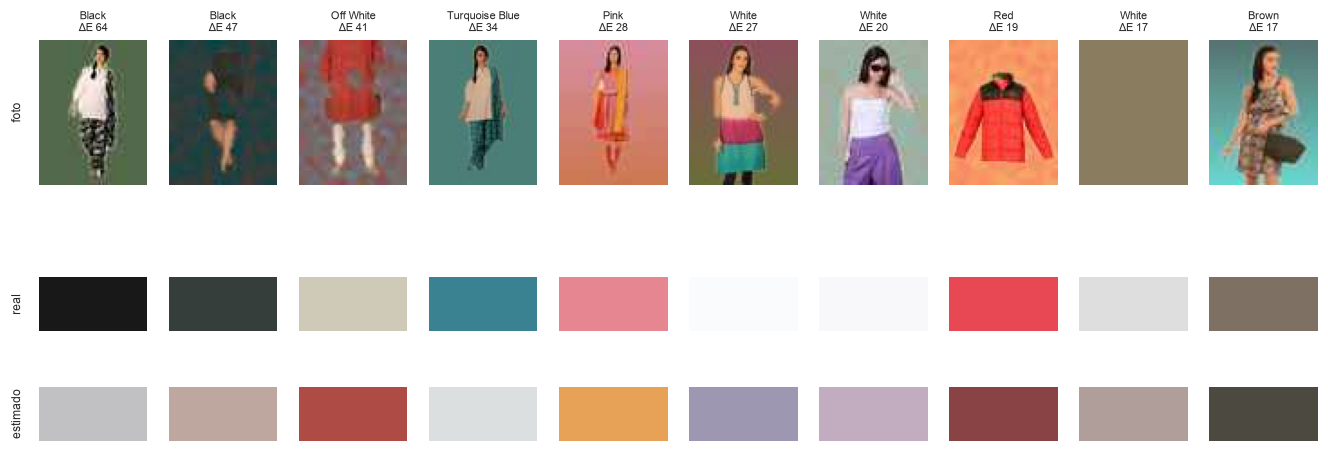

fondo
textura      4
degradado    3
solido       3
Name: count, dtype: int64


In [10]:
peores = ev[ev["tipo"] == "un color, coherente"].nlargest(10, "dE")
fig, axes = plt.subplots(3, 10, figsize=(15, 5.5), gridspec_kw={"height_ratios": [3, 1, 1]})
for k, (pid, r) in enumerate(peores.iterrows()):
    axes[0, k].imshow(decodificar(real.at[pid, "imagen_bytes"])); axes[0, k].set_title(f"{r.baseColour}\nΔE {r.dE:.0f}", fontsize=7)
    axes[1, k].imshow(np.ones((3, 6, 3)) * lab_a_rgb(r[lab_cols].to_numpy(float))[0])
    axes[2, k].imshow(np.ones((3, 6, 3)) * lab_a_rgb(p.loc[pid, ["L", "a", "b"]].to_numpy(float))[0])
for ax in axes.flat: ax.axis("off")
for fila, t_ in zip(axes[:, 0], ["foto", "real", "estimado"]):
    fila.text(-0.15, 0.5, t_, transform=fila.transAxes, rotation=90, va="center", ha="right", fontsize=8)
guardar("p5_peores"); plt.show()
print(real.loc[peores.index, ["fondo", "kelvin", "brillo"]].value_counts("fondo"))

## 8. Demostración para el área comercial: requerimiento → paleta → referencias del catálogo

Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

Loading weights:  14%|█▎        | 52/380 [00:00<00:00, 510.48it/s]

Loading weights:  27%|██▋       | 104/380 [00:00<00:00, 334.56it/s]

Loading weights:  37%|███▋      | 141/380 [00:00<00:00, 253.25it/s]

Loading weights: 100%|██████████| 380/380 [00:00<00:00, 696.38it/s]

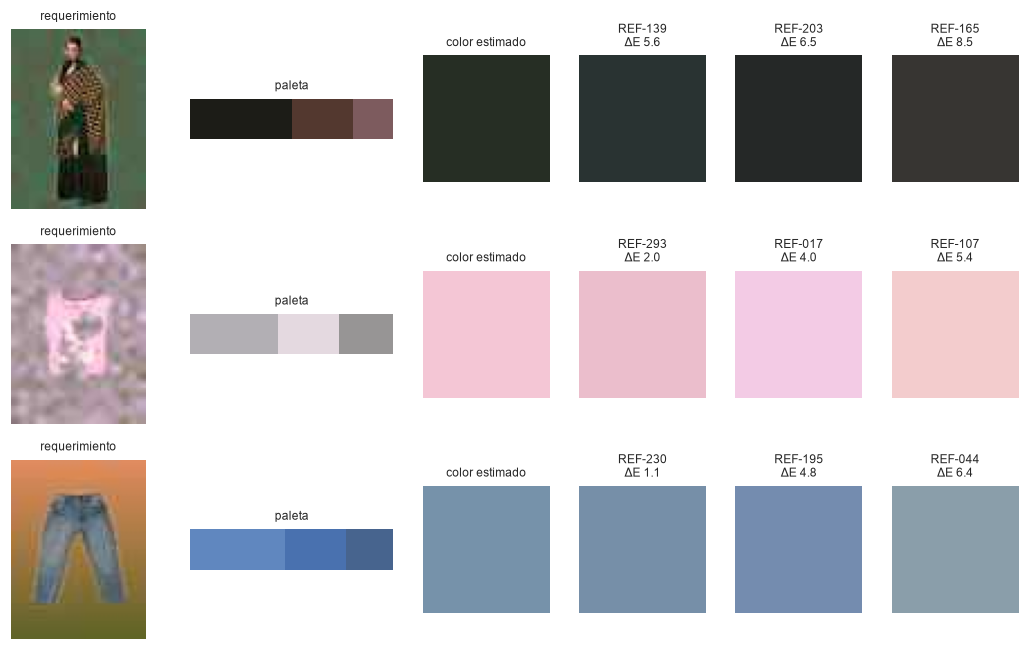

In [11]:
from core.segmentacion import segmentar
from core.objetivo_color import medir_color_prenda, balance_gris
red = redes[MEJOR]
ids = ev[ev["tipo"] == "multicolor"].sample(1, random_state=3).index.tolist() + ev[ev["tipo"] == "un color, coherente"].sample(2, random_state=8).index.tolist()
c_lab = catalogo[["L", "a", "b"]].to_numpy(float)
fig, axes = plt.subplots(len(ids), 6, figsize=(12, 2.4 * len(ids)), gridspec_kw={"width_ratios": [1.3, 1.6, 1, 1, 1, 1]})
for fila, pid in zip(axes, ids):
    rgb = decodificar(real.at[pid, "imagen_bytes"])
    if getattr(red, "tipo", "") == "hibrida":
        lab = predecir_foto(red, rgb)[0]
    else:
        with torch.no_grad():
            lab = red(preparar_tensor(rgb, tam=red.tam)[None])[0][0].numpy() * 100
    o = medir_color_prenda(balance_gris(rgb), segmentar([rgb])[0], tabla.at[pid, "subCategory"], corregir_blancos=False)
    fila[0].imshow(rgb); fila[0].set_title("requerimiento", fontsize=8)
    pal = np.array(o["paleta"]); part = np.array(o["paleta_part"])
    fila[1].imshow(np.concatenate([np.ones((6, max(1, int(round(q * 30))), 3)) * lab_a_rgb(cc)[0] for cc, q in zip(pal, part)], axis=1))
    fila[1].set_title("paleta (multicolor)" if o["multicolor"] else "paleta", fontsize=8)
    fila[2].imshow(np.ones((4, 4, 3)) * lab_a_rgb(lab)[0]); fila[2].set_title("color estimado", fontsize=8)
    d = skcolor.deltaE_ciede2000(lab[None], c_lab); orden = np.argsort(d)[:3]
    for ax, j in zip(fila[3:], orden):
        ax.imshow(np.ones((4, 4, 3)) * lab_a_rgb(c_lab[j])[0]); ax.set_title(f"{catalogo.index[j]}\nΔE {d[j]:.1f}", fontsize=8)
for ax in axes.flat: ax.axis("off")
guardar("p5_demo_comercial"); plt.show()

## 9. Conclusiones y limitaciones

### Conclusiones
1. **Del color discreto al continuo.** La etiqueta `baseColour` define prototipos y filtra incoherencias, pero el objetivo de negocio es un **color CIELAB continuo** medido sobre la prenda segmentada; así el sistema responde a cualquier color del cliente y lo compara por ΔE2000 contra el catálogo.
2. **La línea base por umbral no sirve en el contexto real:** ΔE 5,6 en catálogo pero **19,5 en fotos de cliente**, porque dependía de un fondo blanco.
3. **El mejor modelo es E11, la red híbrida "medir en vez de regresar":** predice *dónde* está el color dominante (atención a la resolución nativa) y *qué luz* tiene la foto (ganancias por canal), y mide el color sobre los píxeles corregidos. **ΔE mediano 2,2 en foto de cliente** (86 % con ΔE < 5, 98 % con ΔE < 10), frente a 3,7 de E10, 4,5 de E9 y 10,4 de E8; estable con luz cálida (2,4) y cualquier fondo (2,2-2,3); sin sesgo de claridad (ΔL* +0,1).
4. **Las mejoras vinieron de analizar los errores, no de cambiar de arquitectura a ciegas:**
   * el techo de la evaluación por prototipo (75 % / 60 %) mostró que el cuello de botella del *nombre* era el método: la cabeza de tonos llevó el top-1 de 58 % a **80 %** (E10);
   * el análisis del error de E10 mostró que una CNN con pooling global no puede escoger píxeles (la máscara exacta reproduce el objetivo con ΔE 0,6; a 1/4 de resolución ya da 3,8): E11 mide sobre los píxeles y baja el error de color un 40 %.
5. **El aumento con iluminantes y fondos manteniendo fijo el objetivo enseña constancia de color.** Grad-CAM lo confirma (E8 mira el fondo; E9 y E10 la prenda) y el mapa de atención de E11 sigue el contorno exacto de la prenda sin máscara manual.
6. **Características congeladas + regresión lineal (E4-E6) no bastan:** codifican forma y escena más que color (ΔE 17-28 en foto de cliente).
7. **Segmentación + k-means (E2)** es la mejor opción sin entrenamiento (ΔE 7,3) y aporta la **paleta** para prendas multicolor; gray-world sin referencia blanca la empeora.

### Limitaciones
* Fotos de cliente y catálogo de colorantes **simulados**; falta validar con requerimientos reales y medición de espectrofotómetro. Con luz y máscara perfectas el piso físico de esta simulación es ΔE ≈ 1,6 (JPEG, altas luces, bordes): E11 está a 0,6 de ese piso.
* Las metas de nombre se cumplen en prendas coherentes de un color; con etiquetas incoherentes o multicolor el nombre es menos confiable. El grupo queda en 86 % (meta 90 %).
* Imágenes de 60 × 80 px; color en pantalla ≠ color del tinte sobre la fibra (metamerismo, sustrato): el sistema **sugiere**, el laboratorio ajusta.
* La segmentación usada para la paleta falla en prendas sin modelo humano sobre fondos de textura.

### Trabajo futuro
Validar con fotos reales de requerimientos y el catálogo real; pedir al cliente una **hoja blanca** en la foto (referencia neutra para Von Kries: el análisis estima ΔE ≈ 1,8 alcanzable); mayor resolución; predecir la paleta completa con la misma arquitectura híbrida (varios mapas de atención).